# Parte II — aplicação da rbg

Prever aluguel e resolver um segundo problema de classificação usando a rbg. Incluir rede neural na comparação.


## 0. Ambiente e dados

Usar pandas e NumPy para preparar os dados e Altair para os gráficos.


In [114]:
from pathlib import Path
import numpy as np
import pandas as pd
import altair as alt

from rbg.Regression.Linear import Linear
from rbg.Regression.Ridge import Ridge
from rbg.Regression.Lasso import Lasso
from rbg.Regression.Polynomial import Polynomial
from rbg.Classification.Logistic import Logistic
from rbg.Utilities import RMSE, RSquare

DATA_REG = Path('dataset_limpo.csv')
DATA_CLASS = Path('CAMINHO_DO_SEGUNDO_DATASET.csv')  # TODO: definir
SEED = 67

## 1. Regressão: aluguel

Prever o aluguel mensal em euros (`rent`) a partir das características do imóvel.


,rent,area,yearc,location,bath,kitchen,cheating,district
0,109.948715,26,1918.0,2,0,0,0,916
1,243.282043,28,1918.0,2,0,0,1,813
2,261.641022,30,1918.0,1,0,0,1,611
3,106.410255,30,1918.0,2,0,0,0,2025
4,133.384613,30,1918.0,2,0,0,1,561


<class 'pandas.DataFrame'>
RangeIndex: 3082 entries, 0 to 3081
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rent      3082 non-null   float64
 1   area      3082 non-null   int64  
 2   yearc     3082 non-null   float64
 3   location  3082 non-null   int64  
 4   bath      3082 non-null   int64  
 5   kitchen   3082 non-null   int64  
 6   cheating  3082 non-null   int64  
 7   district  3082 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 192.8 KB


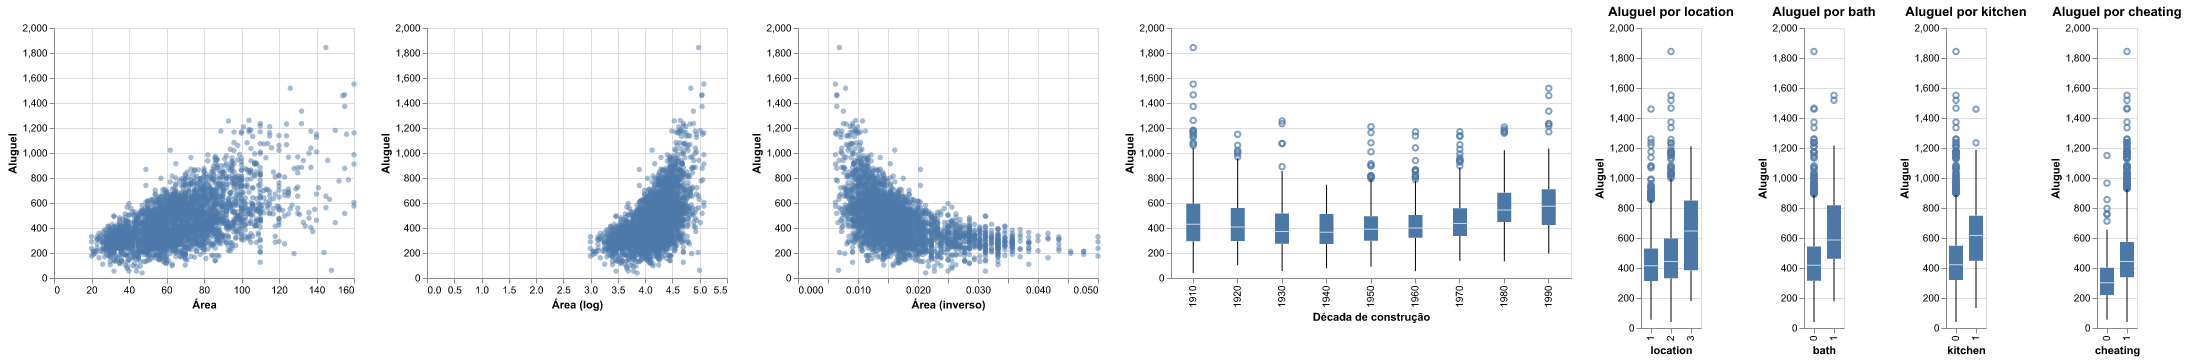

In [115]:
dados_reg = pd.read_csv(DATA_REG)
display(dados_reg.head())
dados_reg.info()

# Dispersão para variáveis numéricas.
alt.renderers.enable('png')

grafico_area_aluguel = alt.Chart(dados_reg).mark_circle(opacity=0.5).encode(
    x=alt.X("area:Q", title="Área"),
    y=alt.Y("rent:Q", title="Aluguel")
).properties(width=300, height=250)

dados_reg["decada"] = (dados_reg["yearc"] // 10 * 10).astype(int)

grafico_decada_aluguel = alt.Chart(dados_reg).mark_boxplot().encode(
    x=alt.X("decada:O", title="Década de construção"),
    y=alt.Y("rent:Q", title="Aluguel")
).properties(width=400, height=250)
dados_reg["log(area)"] = np.log(dados_reg["area"])
dados_reg["inv(area)"] = 1 / dados_reg["area"]

grafico_area_log_aluguel = alt.Chart(dados_reg).mark_circle(opacity=0.5).encode(
    x=alt.X("log(area):Q", title="Área (log)"),
    y=alt.Y("rent:Q", title="Aluguel")
).properties(width=300, height=250)

grafico_area_inversa_aluguel = alt.Chart(dados_reg).mark_circle(opacity=0.5).encode(
    x=alt.X("inv(area):Q", title="Área (inverso)"),
    y=alt.Y("rent:Q", title="Aluguel")
).properties(width=300, height=250)

graficos = [grafico_area_aluguel, grafico_area_log_aluguel, grafico_area_inversa_aluguel, grafico_decada_aluguel]

for coluna in ['location', 'bath', 'kitchen', 'cheating']:
    graficos.append(alt.Chart(dados_reg).mark_boxplot().encode(
        x=alt.X(f'{coluna}:N', title=coluna),
        y=alt.Y('rent:Q', title='Aluguel')
    ).properties(title=f'Aluguel por {coluna}'))




alt.hconcat(*graficos)


### Observações iniciais

Nos gráficos, a relação entre ano de construção e aluguel parece menos evidente. A área na escala original parece se adequar a um ajuste linear. Vou comparar os tipos de ajuste pela validação.


### 1.1 Escolha das variáveis

Vou manter `area` e `yearc` na escala original e `bath`, `kitchen` e `cheating` como 0 ou 1.

Para `location`, vou criar `l2` (1 se location = 2) e `l3` (1 se location = 3), com 0 nos demais casos. A referência será location = 1.

Vou deixar `district`, `decada`, `log(area)` e `inv(area)` de fora nesta comparação.


In [116]:
TARGET_REG = 'rent'
FEATURES_REG = ['area', 'yearc', 'bath', 'kitchen', 'cheating', 'l2', 'l3']
dados_reg["l2"] = (dados_reg["location"] == 2).astype(int)
dados_reg["l3"] = (dados_reg["location"] == 3).astype(int)

dados_reg[["location", "l2", "l3"]].head()


,location,l2,l3
0,2,1,0
1,2,1,0
2,1,0,0
3,2,1,0
4,2,1,0


### 1.2 Separar o teste final

Vou reservar 20% para o teste final. Os 80% restantes serão usados para escolher os modelos com LOOCV.


In [117]:
from rbg.Utilities.crossvalidation import train_test_split

X = dados_reg[FEATURES_REG].to_numpy(dtype=float)
y = dados_reg[TARGET_REG].to_numpy(dtype=float)

X_dev, X_teste, y_dev, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)


### 1.3 Conferir os dados antes dos ajustes

Meus amigos já trataram os dados, mas pedi à IA uma conferência de valores ausentes, valores inválidos e dimensões dos arrays.


In [118]:
# Conferir se há valores ausentes nos dados de treino.
display(pd.DataFrame(X_dev, columns=FEATURES_REG).isna().sum())

# Os arrays precisam ter valores numéricos finitos e dimensões compatíveis.
assert np.isfinite(X_dev).all()
assert np.isfinite(y_dev).all()
assert np.isfinite(X_teste).all()
assert np.isfinite(y_teste).all()
assert X_dev.shape[0] == len(y_dev)
assert X_teste.shape[0] == len(y_teste)
assert X_dev.shape[1] == X_teste.shape[1] == len(FEATURES_REG)

print('Treino:', X_dev.shape, y_dev.shape)
print('Teste:', X_teste.shape, y_teste.shape)


area        0
yearc       0
bath        0
kitchen     0
cheating    0
l2          0
l3          0
dtype: int64

Treino: (2465, 7) (2465,)
Teste: (617, 7) (617,)


### 1.4 Preparar o LOOCV

Vou usar as mesmas rodadas de LOOCV para comparar todos os modelos.


In [119]:
from rbg.ModelSelection.LOOCV import LOOCV

# Cada rodada retorna os índices de treino e depois os de validação.
rodadas = list(LOOCV().split(X_dev))


### 1.5 Ajustar os modelos

Vou testar vários modelos com LOOCV para escolher o mais adequado, variando os valores de `alpha` de Ridge e Lasso e alguns graus polinomiais.


In [120]:
modelos_reg = {'linear': (Linear, {})}

for i in range(0,8):
    alpha = 2 ** (4 - i) 
    modelos_reg[f"ridge_{2}^{4-i}"] = (Ridge, {"alpha": alpha})
    modelos_reg[f"lasso_{2}^{4-i}"] = (Lasso, {"alpha": alpha})

for grau in [2, 3]:
    modelos_reg[f"polinomial_{grau}"] = (
        Polynomial,
        {"degrees": [grau] * X_dev.shape[1]}
    )
# Vou comparar os graus polinomiais pelo desempenho no LOOCV.

resultados_validacao = []

for nome, (classe, parametros) in modelos_reg.items():
    previsoes_loocv = np.empty(len(y_dev))

    for idx_treino, idx_val in rodadas:
        modelo = classe(**parametros)
        modelo.fit(X_dev[idx_treino], y_dev[idx_treino])
        previsoes_loocv[idx_val] = modelo.predict(X_dev[idx_val])

    resultados_validacao.append({
        'modelo': nome,
        'RMSE': RMSE(previsoes_loocv, y_dev),
        'R²': RSquare(previsoes_loocv, y_dev),
    })


### 1.6 Comparar os resultados

Não observei um comportamento polinomial claro na análise inicial. Os polinomiais tiveram RMSE um pouco menor e R² um pouco maior no LOOCV. Isso indica um ganho na validação e não permite concluir que houve overfitting. Mesmo com esse ganho, prefiro o modelo linear pela simplicidade e interpretabilidade.

Ridge, Lasso e Linear tiveram RMSE muito próximos e R² iguais nas quatro casas decimais exibidas. Não vejo vantagem prática na regularização para as configurações testadas e escolho o Linear.


In [121]:
tabela_reg = pd.DataFrame(resultados_validacao).sort_values('RMSE').reset_index(drop=True)
display(tabela_reg.round(4))
melhor_modelo = 'linear'  # Escolha pela simplicidade e interpretabilidade.


,modelo,RMSE,R²
0,polinomial_2,135.7078,0.4963
1,polinomial_3,135.8288,0.4954
2,ridge_2^3,138.7827,0.4732
3,ridge_2^4,138.7831,0.4732
4,ridge_2^2,138.7831,0.4732
5,ridge_2^1,138.7835,0.4732
6,ridge_2^0,138.7837,0.4732
7,ridge_2^-1,138.7838,0.4732
8,ridge_2^-2,138.7838,0.4732
9,ridge_2^-3,138.7839,0.4732


### 1.7 Avaliação final

Vou treinar o modelo escolhido em todos os dados de treino e avaliar seu desempenho no teste com RMSE, R² e gráficos de resíduos.


In [122]:
modelo_final = Linear()

modelo_final.fit(X_dev, y_dev)
previsoes_teste = modelo_final.predict(X_teste)

print(f"Já com o modelo linear escolhido, RMSE: {RMSE(previsoes_teste, y_teste):.4f}, R²: {RSquare(previsoes_teste, y_teste):.4f}")

inferencia = modelo_final.inference()

Já com o modelo linear escolhido, RMSE: 148.8149, R²: 0.5089


#### 1.7.1 Desempenho no teste

Vou avaliar o desempenho do modelo linear. No gráfico, pontos próximos da diagonal indicam previsões próximas do aluguel real.


In [123]:
beta, sigma2, cov_beta, residuos_dev = inferencia
previsoes_dev = modelo_final.predict(X_dev)

metricas_finais = pd.DataFrame([
    {'modelo': 'Linear — treino',
     'RMSE': RMSE(previsoes_dev, y_dev), 'R²': RSquare(previsoes_dev, y_dev)},
    {'modelo': 'Linear — teste',
     'RMSE': RMSE(previsoes_teste, y_teste), 'R²': RSquare(previsoes_teste, y_teste)}
])
display(metricas_finais.round(4))


,modelo,RMSE,R²
0,Linear — treino,138.1362,0.4781
1,Linear — teste,148.8149,0.5089


O modelo linear me parece ter feito um ajuste razoável nos dados de teste, pelo desempenho próximo ao do treino. O gráfico abaixo mostra que ele não funcionou tão bem para aluguéis muito altos.


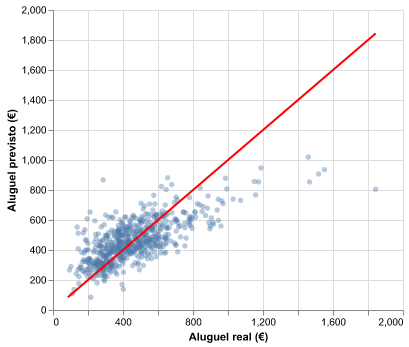

In [124]:
dados_teste = pd.DataFrame({'real': y_teste, 'previsto': previsoes_teste})
limites = [min(y_teste.min(), previsoes_teste.min()),
           max(y_teste.max(), previsoes_teste.max())]
diagonal = pd.DataFrame({'valor': limites})

grafico_real_previsto = alt.Chart(dados_teste).mark_circle(opacity=0.4).encode(
    x=alt.X('real:Q', title='Aluguel real (€)', scale=alt.Scale(domain=limites)),
    y=alt.Y('previsto:Q', title='Aluguel previsto (€)', scale=alt.Scale(domain=limites))
)
grafico_linha_ideal = alt.Chart(diagonal).mark_line(color='red').encode(
    x='valor:Q', y='valor:Q'
)
display((grafico_real_previsto + grafico_linha_ideal).properties(width=350, height=300))


#### 1.7.2 Resíduos

Vou usar os resíduos retornados por `modelo_final.inference()`, que correspondem ao treino. Espero pontos espalhados em torno de zero, sem curvatura ou formato de funil. O histograma ajuda a observar assimetria e erros extremos.

O formato de funil nos resíduos é preocupante: sugere que a variância dos erros aumenta com o aluguel previsto, contrariando a hipótese de variância constante. O histograma não permite confirmar a normalidade, mas seu formato me parece razoável.


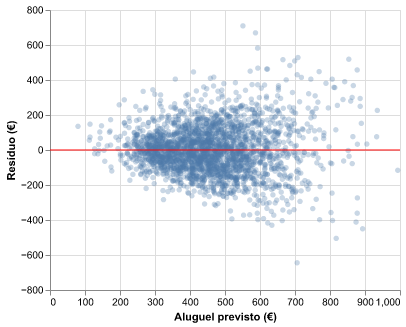

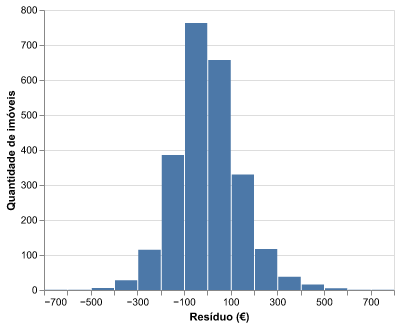

In [125]:
dados_residuos = pd.DataFrame({
    'previsto': previsoes_dev,
    'residuo': residuos_dev
})

grafico_residuos_previstos = alt.Chart(dados_residuos).mark_circle(opacity=0.3).encode(
    x=alt.X('previsto:Q', title='Aluguel previsto (€)'),
    y=alt.Y('residuo:Q', title='Resíduo (€)')
)
grafico_linha_zero = alt.Chart(pd.DataFrame({'zero': [0]})).mark_rule(color='red').encode(
    y='zero:Q'
)
display((grafico_residuos_previstos + grafico_linha_zero).properties(width=350, height=280))

grafico_histograma_residuos = alt.Chart(dados_residuos).mark_bar().encode(
    x=alt.X('residuo:Q', bin=alt.Bin(maxbins=25), title='Resíduo (€)'),
    y=alt.Y('count():Q', title='Quantidade de imóveis')
)
display(grafico_histograma_residuos.properties(width=350, height=280))


#### 1.7.3 Betas na escala original e padronizada


Vou exibir os coeficientes originais e os padronizados por β × desvio da variável / desvio do aluguel.


In [126]:
beta, sigma2, cov_beta, residuos_dev = inferencia
coeficientes = beta[1:]
coeficientes_padronizados = coeficientes * X_dev.std(axis=0) / y_dev.std()

comparacao_coeficientes = pd.DataFrame({
    'variavel': FEATURES_REG,
    'beta_original': coeficientes,
    'beta_padronizado': coeficientes_padronizados
})
display(comparacao_coeficientes.round(4))

betas = comparacao_coeficientes.set_index('variavel')


,variavel,beta_original,beta_padronizado
0,area,4.9023,0.5993
1,yearc,1.7753,0.2064
2,bath,56.9311,0.0712
3,kitchen,88.3342,0.0898
4,cheating,113.3608,0.1787
5,l2,52.4690,0.1344
6,l3,135.4296,0.1126


O `beta_original` indica quanto o valor previsto muda com o aumento de uma unidade da variável contínua, mantendo as outras fixas. Nas variáveis binárias, indica a diferença prevista entre os casos 1 e 0. Para `l2` e `l3`, a comparação é com `location = 1`.

Já o beta padronizado permite comparar o tamanho das associações em uma mesma escala. Aqui, a área tem o maior valor, seguida pelo ano, `cheating`, `l2` e `l3`. Os valores de `kitchen` e `bath` são menores. 


#### 1.7.4 Coeficientes

Aqui vou usar `cov_beta` para ter uma ideia da incerteza de cada beta. A raiz da diagonal dá os erros padrão. Com eles, vou calcular intervalos de 95% aproximados usando beta ± 1,96 × erro padrão, mantendo a escala original.

Esses intervalos pressupõem erros não correlacionados e variância constante. Como os resíduos mostraram um formato de funil, vou interpretar os intervalos com cuidado.


In [127]:
beta, sigma2, cov_beta, residuos_dev = inferencia

# Coeficientes na escala original, sem o intercepto.
coeficientes = beta[1:]
erros_padrao = np.sqrt(np.diag(cov_beta)[1:])

tabela_coeficientes = pd.DataFrame({
    'variavel': FEATURES_REG,
    'coeficiente': coeficientes,
    'erro_padrao': erros_padrao,
    'inferior': coeficientes - 1.96 * erros_padrao,
    'superior': coeficientes + 1.96 * erros_padrao
})
display(tabela_coeficientes.round(4))


,variavel,coeficiente,erro_padrao,inferior,superior
0,area,4.9023,0.1269,4.6535,5.1511
1,yearc,1.7753,0.1398,1.5013,2.0494
2,bath,56.9311,12.0916,33.2315,80.6307
3,kitchen,88.3342,14.4162,60.0783,116.5900
4,cheating,113.3608,9.9313,93.8955,132.8261
5,l2,52.4690,5.8350,41.0324,63.9056
6,l3,135.4296,17.7738,100.5930,170.2663


## 2. Classificação

Escolher outro conjunto público, definir o alvo e preparar os dados. Usar `Logistic(classes=...)` da rbg.


In [128]:
# dados_class = pd.read_csv(DATA_CLASS)  # TODO: escolher o segundo conjunto
TARGET_CLASS = None  # TODO: nome da variável alvo
# TODO: explorar frequências das classes, ausências, duplicatas e vazamentos.
# TODO: separar treino, validação e teste; estratificar se apropriado.
# TODO: ajustar pré-processamento apenas no treino.
# classes = np.unique(y_class_train)
# modelo_logistico = Logistic(classes=classes)
# modelo_logistico.fit(X_class_train, y_class_train)
# probabilidades = modelo_logistico.predict_proba(X_class_val)
# previsoes_class_val = modelo_logistico.predict(X_class_val)


### 2.1 Comparação e avaliação final

Comparar os classificadores com a previsão da classe mais frequente. Escolher as métricas, validar os modelos e avaliar o escolhido no teste final.


In [129]:
# TODO: comparar modelos e hiperparâmetros na validação.
# TODO: incluir rede neural como exige o enunciado, quando a implementação estiver disponível.
# TODO: avaliação final da classificação no teste e interpretação dos erros.


## 3. Registro do experimento

Registrar origem dos dados, divisão, transformações, hiperparâmetros, resultados e limitações.
